# ViT: An Image is Worth 16×16 Words (Dosovitskiy et al., 2020)

For a decade, vision meant convolutions. A CNN builds in two assumptions about
images: **locality** (nearby pixels matter together) and **translation
equivariance** (a cat is a cat wherever it appears). Those assumptions are why
CNNs learn well from limited data.

The Vision Transformer asks what happens if you drop both. Cut the image into
16×16 patches, flatten each into a vector, treat the sequence of patches like
the words of a sentence, and hand it to an unmodified
[Transformer encoder](/how-models-work/bert-pre-training-of-deep-bidirectional-transformers/).
The answer the paper gives has two halves:

* Trained on ImageNet alone (1.3M images), ViT **loses** to comparable ResNets.
* Pre-trained on 14M (ImageNet-21k) or 300M (JFT-300M) images, it **wins**, and
  at lower pre-training cost. ViT-H/14 reached 88.55% top-1 on ImageNet.

*Large-scale training trumps inductive bias.* This page builds the patch
pipeline, counts the paper's model sizes, and reproduces the data-hunger
result at small scale.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from hmw_motion import Scene, mix

torch.manual_seed(0); np.random.seed(0)
torch.set_num_threads(4)


def banner(title):
    print("=" * 78); print(f"  {title}"); print("=" * 78)


def step(label):
    print(); print(label); print("-" * 78)


def check(label, ok):
    print(f"  [{'PASS' if ok else 'FAIL'}] {label}")
    return ok


print("helpers ready")

helpers ready


## 1. From image to token sequence

For an image of size $H \times W \times C$ and patch size $P$:

$$N = \frac{HW}{P^2} \text{ patches}, \qquad \text{each flattened to } P^2 C \text{ numbers}$$

A 224×224 RGB image with $P = 16$ gives $14 \times 14 = 196$ patches of
$16 \cdot 16 \cdot 3 = 768$ numbers each. A learned linear map, the *patch
embedding*, projects each to the model width $D$. A learnable `[class]` token
is prepended, as in BERT, giving 197 tokens, and a learned position embedding
is added to each.

The patch split is just a reshape. The cell checks that it matches cutting the
patches out by hand.

In [2]:
banner("PATCHIFY A 224 x 224 x 3 IMAGE")
img = np.random.default_rng(0).random((224, 224, 3))
P = 16


def patchify(x, P):
    H, W, C = x.shape
    return x.reshape(H // P, P, W // P, P, C).transpose(0, 2, 1, 3, 4).reshape(-1, P * P * C)


seq = patchify(img, P)
by_hand = np.stack([img[i:i + P, j:j + P].reshape(-1) for i in range(0, 224, P) for j in range(0, 224, P)])
print(f"  image {img.shape}  ->  sequence {seq.shape}  (patches x numbers per patch)")
check("reshape-based patchify == slicing patches out one by one, row-major", np.array_equal(seq, by_hand))
print(f"  plus [class] token: {seq.shape[0] + 1} tokens per image")
print(f"  patch 16 -> {(224//16)**2} tokens;  patch 14 -> {(224//14)**2};  patch 32 -> {(224//32)**2}")
print("  Halving the patch size quadruples the sequence length, and attention cost grows with its square.")

  PATCHIFY A 224 x 224 x 3 IMAGE
  image (224, 224, 3)  ->  sequence (196, 768)  (patches x numbers per patch)
  [PASS] reshape-based patchify == slicing patches out one by one, row-major
  plus [class] token: 197 tokens per image
  patch 16 -> 196 tokens;  patch 14 -> 256;  patch 32 -> 49
  Halving the patch size quadruples the sequence length, and attention cost grows with its square.


In [3]:
def patch_scene():
    dg = load_digits()
    im = dg.images[3] / 16.0
    ps, cs = 2, 30
    sc = Scene(720, 400, dur=10.0, caption="An 8x8 digit as a sequence: 16 patches of 2x2, a [class] token, positions",
               poster=9.5)
    ox, oy = 40, 70
    sc.text(ox + 4 * cs, 46, "image (8 x 8)", size=13, fill="muted")
    for i in range(8):                                   # faint copy stays behind as a reference
        for j in range(8):
            sc.rect(ox + j * cs, oy + i * cs, cs - 2, cs - 2, fill=mix("bg", "white", im[i, j]), rx=3,
                    opacity=0).to(3.4, 4.4, opacity=0.18)
    seq_y, x0 = 300, 74
    slot_w = 38
    for pi in range(4):
        for pj in range(4):
            k = pi * 4 + pj
            tx = x0 + (k + 1) * slot_w
            for a in range(ps):
                for b in range(ps):
                    i, j = pi * ps + a, pj * ps + b
                    c = sc.rect(ox + j * cs, oy + i * cs, cs - 2, cs - 2, fill=mix("bg", "white", im[i, j]), rx=3)
                    sx = tx + b * 15
                    sy = seq_y + a * 15
                    c.to(1.2 + 0.08 * k, 2.6 + 0.08 * k, x=ox + j * cs + pj * 10, y=oy + i * cs + pi * 10)
                    c.to(3.4 + 0.1 * k, 5.0 + 0.1 * k, x=sx, y=sy, w=13, h=13, rx=2)
            sc.text(tx + 14, seq_y + 46, str(k + 1), size=11, fill="amber", opacity=0).fade_in(6.4 + 0.04 * k)
            bar = sc.rect(tx, seq_y - 18, 28, 0, fill="violet", rx=2, opacity=0)
            bar.to(7.6 + 0.04 * k, 8.4 + 0.04 * k, y=seq_y - 70, h=52, opacity=0.9)
    cls = sc.rect(x0 - 2, seq_y, 30, 30, fill=mix("panel", "green", 0.6), stroke="green", sw=1.5, rx=4, opacity=0)
    cls.to(5.6, 6.2, opacity=1, ease="back")
    sc.text(x0 + 13, seq_y + 15, "C", size=13, fill="white", weight=700, opacity=0).fade_in(5.8)
    sc.text(x0 + 13, seq_y + 46, "0", size=11, fill="amber", opacity=0).fade_in(6.4)
    sc.bar_ = sc.rect(x0 - 1, seq_y - 18, 28, 0, fill="green", rx=2, opacity=0)
    sc.bar_.to(7.6, 8.4, y=seq_y - 70, h=52, opacity=0.9)
    sc.text(420, 150, "each patch -> one vector of width D", size=13, fill="violet", anchor="start", opacity=0).fade_in(7.8)
    sc.text(420, 172, "(patch embedding + position embedding)", size=12, fill="amber", anchor="start", opacity=0).fade_in(7.8)
    sc.beat(0.0, "The image as pixels.")
    sc.beat(1.2, "Cut it into non-overlapping 2x2 patches (16x16 in the paper).")
    sc.beat(3.4, "Line the patches up row by row: the image is now a sequence of 16 tokens.")
    sc.beat(5.6, "Prepend a learnable [class] token, and number every position.")
    sc.beat(7.6, "Each flattened patch is linearly projected to width D. From here on, it is BERT.")
    return sc

patch_scene()

<motion scene: An 8x8 digit as a sequence: 16 patches of 2x2, a [class] token, positions (167 elements, 10s)>

## 2. The paper's models, counted

| Model | Layers | Width $D$ | MLP | Heads | Paper |
|---|---|---|---|---|---|
| ViT-Base | 12 | 768 | 3072 | 12 | 86M |
| ViT-Large | 24 | 1024 | 4096 | 16 | 307M |
| ViT-Huge | 32 | 1280 | 5120 | 16 | 632M |

"ViT-L/16" means the Large model with 16×16 patches. Counting the patch
embedding, `[class]` token, position table, encoder layers and final layer norm,
and leaving out the task-specific classification head:

In [4]:
banner("COUNTING ViT PARAMETERS (224 x 224 input, no classification head)")
def vit_params(L, D, M, P, img=224, C=3):
    N = (img // P) ** 2
    patch = P * P * C * D + D
    cls, pos = D, (N + 1) * D
    layer = (4 * D * D + 4 * D) + (2 * D * M + M + D) + 4 * D
    return patch + cls + pos + L * layer + 2 * D

for name, L, D, M, P_, rep in [("ViT-B/16", 12, 768, 3072, 16, 86e6), ("ViT-L/16", 24, 1024, 4096, 16, 307e6),
                               ("ViT-H/14", 32, 1280, 5120, 14, 632e6)]:
    n = vit_params(L, D, M, P_)
    print(f"  {name:<9} {n:>13,}  = {n/1e6:6.1f}M   (paper: {rep/1e6:.0f}M, {100*(n-rep)/rep:+.1f}%)")
print("\n  Nearly all of it is the encoder: the patch embedding of ViT-B/16 is only "
      f"{(768*768+768)/vit_params(12,768,3072,16)*100:.1f}% of the total.")

  COUNTING ViT PARAMETERS (224 x 224 input, no classification head)
  ViT-B/16     85,798,656  =   85.8M   (paper: 86M, -0.2%)
  ViT-L/16    303,301,632  =  303.3M   (paper: 307M, -1.2%)
  ViT-H/14    630,764,800  =  630.8M   (paper: 632M, -0.2%)

  Nearly all of it is the encoder: the patch embedding of ViT-B/16 is only 0.7% of the total.


## 3. Data hunger, reproduced in miniature

The paper's central finding is a crossover. With little data the CNN's built-in
assumptions help, and ViT, which must *learn* that neighbouring pixels are
related, falls behind. With enough data that handicap disappears.

The miniature version: 8×8 digits, a small ViT (2×2 patches, so 16 tokens,
plus `[class]`; 4 layers, $D = 64$) against a small CNN with a **comparable
parameter count**. Both are trained on 100, 300 and 1,000 images and tested on
the same 597 held-out images, averaged over 3 seeds.

  ViT parameters: 136,138   CNN parameters: 124,778
  ViT vs CNN AS THE TRAINING SET GROWS
    100 training images:  CNN 0.915 ± 0.011   ViT 0.592 ± 0.025   CNN lead +32.2 points
    300 training images:  CNN 0.969 ± 0.002   ViT 0.838 ± 0.020   CNN lead +13.2 points
   1000 training images:  CNN 0.987 ± 0.005   ViT 0.924 ± 0.015   CNN lead +6.3 points
  [PASS] with 100 images the CNN leads
  [PASS] the CNN's lead shrinks as data grows (100 -> 1,000 images)


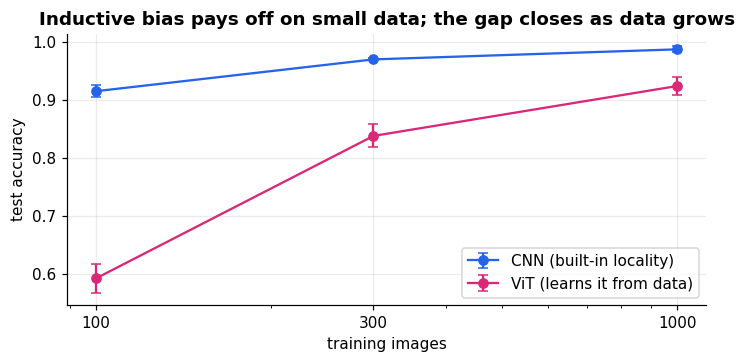

In [5]:
dg = load_digits()
Xall = torch.tensor(dg.images / 16.0, dtype=torch.float32)
yall = torch.tensor(dg.target)
Xtr_all, Xte, ytr_all, yte = train_test_split(Xall, yall, test_size=597, random_state=0, stratify=yall)


class Block(nn.Module):
    def __init__(self, D, H):
        super().__init__()
        self.H = H
        self.ln1, self.ln2 = nn.LayerNorm(D), nn.LayerNorm(D)
        self.qkv, self.o = nn.Linear(D, 3 * D), nn.Linear(D, D)
        self.mlp = nn.Sequential(nn.Linear(D, 2 * D), nn.GELU(), nn.Linear(2 * D, D))
        self.last_attn = None

    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(D, 2)
        sp = lambda t: t.view(B, T, self.H, D // self.H).transpose(1, 2)
        a = (sp(q) @ sp(k).transpose(-2, -1) / (D // self.H) ** .5).softmax(-1)
        self.last_attn = a.detach()
        x = x + self.o((a @ sp(v)).transpose(1, 2).reshape(B, T, D))
        return x + self.mlp(self.ln2(x))


class ViT(nn.Module):
    def __init__(self, D=64, L=4, H=4, P=2):
        super().__init__()
        self.P = P
        n = (8 // P) ** 2
        self.embed = nn.Linear(P * P, D)
        self.cls = nn.Parameter(torch.zeros(1, 1, D))
        self.pos = nn.Parameter(torch.randn(1, n + 1, D) * 0.02)
        self.blocks = nn.ModuleList([Block(D, H) for _ in range(L)])
        self.ln, self.head = nn.LayerNorm(D), nn.Linear(D, 10)

    def forward(self, img):
        B, P = len(img), self.P
        x = img.view(B, 8 // P, P, 8 // P, P).permute(0, 1, 3, 2, 4).reshape(B, -1, P * P)
        x = torch.cat([self.cls.expand(B, 1, -1), self.embed(x)], 1) + self.pos
        for b in self.blocks:
            x = b(x)
        return self.head(self.ln(x[:, 0]))


class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1, self.c2, self.c3 = nn.Conv2d(1, 32, 3, padding=1), nn.Conv2d(32, 64, 3, padding=1), nn.Conv2d(64, 96, 3, padding=1)
        self.fc = nn.Sequential(nn.Linear(96 * 2 * 2, 128), nn.ReLU(), nn.Linear(128, 10))

    def forward(self, img):
        x = F.relu(self.c1(img[:, None]))
        x = F.max_pool2d(F.relu(self.c2(x)), 2)
        x = F.max_pool2d(F.relu(self.c3(x)), 2)
        return self.fc(x.flatten(1))


nv, nc = sum(p.numel() for p in ViT().parameters()), sum(p.numel() for p in CNN().parameters())
print(f"  ViT parameters: {nv:,}   CNN parameters: {nc:,}")


def train_eval(kind, n, seed, steps=1500):
    torch.manual_seed(seed)
    idx = torch.randperm(len(Xtr_all), generator=torch.Generator().manual_seed(seed))[:n]
    Xs, ys = Xtr_all[idx], ytr_all[idx]
    m = ViT() if kind == "vit" else CNN()
    opt = torch.optim.AdamW(m.parameters(), lr=1e-3, weight_decay=0.05)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for it in range(steps):
        b = torch.randint(0, n, (min(64, n),))
        xb = Xs[b]
        shift = torch.randint(-1, 2, (2,))                      # light augmentation for both models
        xb = torch.roll(xb, shifts=(int(shift[0]), int(shift[1])), dims=(1, 2))
        loss = F.cross_entropy(m(xb), ys[b])
        opt.zero_grad(); loss.backward(); opt.step(); sch.step()
    m.eval()
    with torch.no_grad():
        return (m(Xte).argmax(1) == yte).float().mean().item(), m


banner("ViT vs CNN AS THE TRAINING SET GROWS")
table = {}
models = {}
for n in [100, 300, 1000]:
    for kind in ["cnn", "vit"]:
        accs = []
        for s in range(3):
            a, m = train_eval(kind, n, s)
            accs.append(a)
        models[(kind, n)] = m
        table[(kind, n)] = (np.mean(accs), np.std(accs))
    gap = table[("cnn", n)][0] - table[("vit", n)][0]
    print(f"  {n:>5} training images:  CNN {table[('cnn', n)][0]:.3f} ± {table[('cnn', n)][1]:.3f}   "
          f"ViT {table[('vit', n)][0]:.3f} ± {table[('vit', n)][1]:.3f}   CNN lead {100*gap:+.1f} points")
g100 = table[("cnn", 100)][0] - table[("vit", 100)][0]
g1000 = table[("cnn", 1000)][0] - table[("vit", 1000)][0]
check("with 100 images the CNN leads", g100 > 0)
check("the CNN's lead shrinks as data grows (100 -> 1,000 images)", g1000 < g100)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ns = [100, 300, 1000]
for kind, col, lab in [("cnn", "#2563eb", "CNN (built-in locality)"), ("vit", "#db2777", "ViT (learns it from data)")]:
    ax.errorbar(ns, [table[(kind, n)][0] for n in ns], yerr=[table[(kind, n)][1] for n in ns], fmt="o-",
                capsize=3, color=col, label=lab)
ax.set_xscale("log"); ax.set_xticks(ns); ax.set_xticklabels(ns)
ax.set_xlabel("training images"); ax.set_ylabel("test accuracy"); ax.legend()
ax.set_title("Inductive bias pays off on small data; the gap closes as data grows")

## 4. What the position embeddings learned

ViT's position embeddings are plain learned vectors, one per patch slot, with no
built-in notion of 2-D layout. The paper's Figure 7 shows that after training
on large data they **rediscover the grid**: each position's embedding is most
similar to those in the same row and column.

The cell measures the same thing on the model trained with 1,000 images. It
takes the cosine similarity between every pair of position embeddings and
correlates it with how close the two patches are on the 4×4 grid.

  DO THE LEARNED POSITIONS KNOW THE 2-D LAYOUT?
  correlation between embedding similarity and grid closeness: r = 0.342
  patches 1 step  apart: mean cosine similarity +0.340
  patches 2 steps apart: mean cosine similarity -0.090
  patches 3 steps apart: mean cosine similarity -0.207
  patches 4 steps apart: mean cosine similarity -0.125
  [PASS] neighbouring patches have more similar embeddings than distant ones (r > 0)


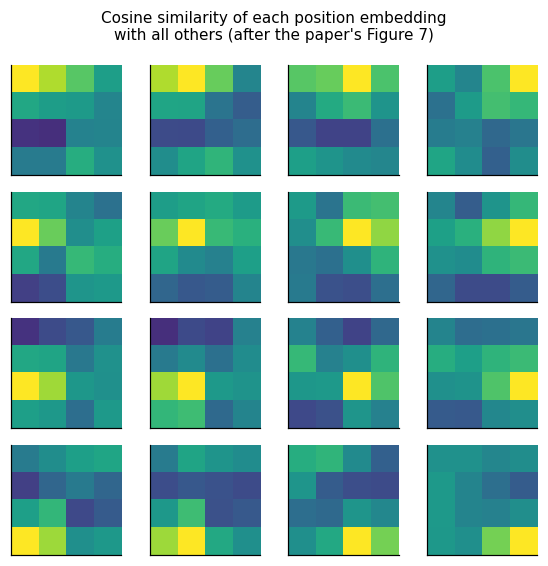

In [6]:
banner("DO THE LEARNED POSITIONS KNOW THE 2-D LAYOUT?")
vit = models[("vit", 1000)]
pe = vit.pos[0, 1:].detach()
pe = pe / pe.norm(dim=1, keepdim=True)
cos = (pe @ pe.T).numpy()
coords = np.array([(i // 4, i % 4) for i in range(16)])
dist = np.abs(coords[:, None] - coords[None]).sum(-1)
mask = ~np.eye(16, dtype=bool)
r = np.corrcoef(cos[mask], -dist[mask])[0, 1]
print(f"  correlation between embedding similarity and grid closeness: r = {r:.3f}")
for d_ in range(1, 5):
    print(f"  patches {d_} step{'s' if d_ > 1 else ' '} apart: mean cosine similarity {cos[mask & (dist == d_)].mean():+.3f}")
check("neighbouring patches have more similar embeddings than distant ones (r > 0)", r > 0)

fig, axes = plt.subplots(4, 4, figsize=(5.2, 5.2))
for i in range(16):
    ax = axes[i // 4, i % 4]
    ax.imshow(cos[i].reshape(4, 4), cmap="viridis", vmin=-1, vmax=1)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Cosine similarity of each position embedding\nwith all others (after the paper's Figure 7)", fontsize=10)
fig.tight_layout()

## 5. Where the `[class]` token looks

In the last layer, the `[class]` token's attention weights over the 16 patches
show which parts of the image the classification draws on. The animation steps
through test digits, showing the trained model's real attention (averaged over
heads) as a heat overlay.

In [7]:
def attn_scene():
    with torch.no_grad():
        vit(Xte[:12])
        A = vit.blocks[-1].last_attn.mean(1)[:, 0, 1:]               # [class] -> patches
        pred = vit(Xte[:12]).argmax(1)
    picks = [i for i in range(12) if pred[i] == yte[i]][:6]
    sc = Scene(720, 380, dur=0.6 + len(picks) * 1.6 + 0.4,
               caption="Last-layer attention from [class] to the 16 patches, trained ViT, test digits",
               poster=0.6 + 3 * 1.6)
    cs = 34
    ox, oy = 60, 50
    first = Xte[picks[0]].numpy()
    pix = [[sc.rect(ox + j * cs, oy + i * cs, cs - 2, cs - 2, fill=mix("bg", "white", first[i, j]), rx=3)
            for j in range(8)] for i in range(8)]
    ax_ = 420
    sc.text(ax_ + 2 * 2 * cs * 0.9, oy - 18, "attention from [class]", size=12, fill="amber")
    a0 = A[picks[0]].numpy()
    heat = [sc.rect(ax_ + (k % 4) * 2 * cs * 0.9, oy + (k // 4) * 2 * cs * 0.9, 2 * cs * 0.9 - 4, 2 * cs * 0.9 - 4,
                    fill=mix("bg", "amber", a0[k] / a0.max()), rx=5) for k in range(16)]
    lab = sc.text(ox + 4 * cs, oy + 8 * cs + 26, f"true {int(yte[picks[0]])}, predicted {int(pred[picks[0]])}",
                  size=13, fill="green")
    for n_, i in enumerate(picks[1:], 1):
        t0 = 0.6 + n_ * 1.6
        im = Xte[i].numpy(); a = A[i].numpy()
        for r_ in range(8):
            for c_ in range(8):
                pix[r_][c_].to(t0, t0 + 0.5, fill=mix("bg", "white", im[r_, c_]))
        for k in range(16):
            heat[k].to(t0, t0 + 0.5, fill=mix("bg", "amber", a[k] / a.max()))
        lab.set(t0 + 0.25, s=f"true {int(yte[i])}, predicted {int(pred[i])}")
    sc.beat(0.0, "Left: a test digit. Right: how much the [class] token attends to each 2x2 patch.")
    sc.beat(2.2, "The weights change from digit to digit, often, though not always, on patches the stroke crosses.")
    return sc

attn_scene()

<motion scene: Last-layer attention from [class] to the 16 patches, trained ViT, test digits (82 elements, 10.6s)>

## Summary

* ViT turns an image into a sequence: $HW/P^2$ flattened patches, linearly
  embedded, plus a `[class]` token and learned positions. The rest is a
  standard Transformer encoder. The reshape-based patchify was checked against
  cutting patches out by hand.
* Counted from their configurations, ViT-B/16, L/16 and H/14 come to 85.8M,
  303M and 631M parameters, matching the paper's 86M, 307M and 632M to within
  about 1%.
* Without convolutions' locality and translation equivariance, ViT needs more
  data. In miniature, a CNN of similar size led at 100 training images and its
  lead shrank as data grew, the same direction as the paper's crossover at
  ImageNet-21k / JFT scale.
* The learned position embeddings partly recovered the 2-D layout on their own,
  even at this size: neighbouring patches average +0.34 cosine similarity and
  patches three steps apart -0.21 (correlation with grid closeness r = 0.34).
* Descendants: DeiT (data-efficient training with distillation), Swin (local
  windows, which reintroduce some locality), MAE (BERT-style masked
  pre-training for images), and the vision encoders of today's multimodal
  models.